In [1]:
%pip install matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


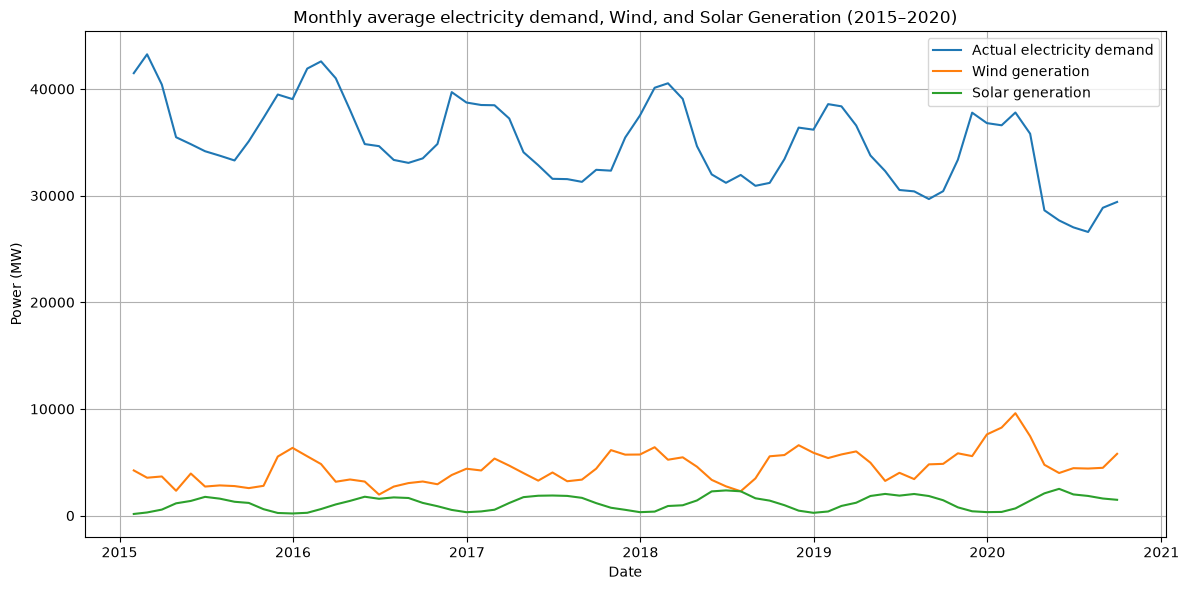

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('cleaned_data.csv')
df['utc_timestamp'] = pd.to_datetime(df['utc_timestamp'])
df = df.set_index('utc_timestamp')

monthly = df[[
    'GB_GBN_load_actual_entsoe_transparency',
    'GB_GBN_wind_generation_actual',
    'GB_GBN_solar_generation_actual'
]].resample('ME').mean()

plt.figure(figsize=(12, 6))
plt.plot(monthly.index, monthly['GB_GBN_load_actual_entsoe_transparency'], label='Actual electricity demand')
plt.plot(monthly.index, monthly['GB_GBN_wind_generation_actual'], label='Wind generation')
plt.plot(monthly.index, monthly['GB_GBN_solar_generation_actual'], label='Solar generation')

plt.title('Monthly average electricity demand, Wind, and Solar Generation (2015–2020)')
plt.xlabel('Date')
plt.ylabel('Power (MW)')
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig('time_series_demand_renewables.png', dpi=300)
plt.show()

Time-Series Line Chart Interpretation:

Actual electricity demand shows a clear seasonal cycle. It goes up every winter (above 40,000 MW in early 2015 and 2016) and drops every summer, while trending downward overall through 2020. 

Wind generation follows a similar winter-peak pattern and goes up over time (reaching nearly 10,000 MW in early 2020), whereas solar generation increases each summer and remains much smaller. 

This is important because the seasonal balance between winter wind and summer solar helps stabilize renewable supply across the year, however, using monthly averages hides short-term hourly spikes and missing data gaps.
